# Estimating $H$ from one path with the quantum nondecimated wavelet transform

**Symmlet 4 with 1,024 input samples and six detail levels.**

This example follows *QuantumHurst (8)*, Sections 3–5 and Appendix A, and uses the coherent shift-register construction of [Vidakovic (2025)](https://arxiv.org/abs/2512.21478). Here \(n=1024\) is the original record length and \(N=2048\) is its length after mirroring. We generate one fractional Brownian path with \(H_0=0.5\) (standard Brownian motion at integer times), then apply the eight-tap Symmlet 4 (sym4) wavelet transform with six detail levels and 64 coherent shifts. Each ancilla level test uses 131,072 shots, for 786,432 total shots across the six levels.

The Mallat window is $j=5,\ldots,10$, with $j=10$ the finest. The circuit itself stops after six levels.

A NumPy statevector simulator applies the mirror, controlled shifts, sym4 paraunitary lattice, and ancilla gates. We sample only the ancilla. The fit uses those counts and an exact covariance calibration computed from the fBm model across candidate values of (H). True (H_0), the path norm, and exact simulated shares are used for generation or diagnostics only. The notebook requires NumPy, SciPy and Matplotlib.

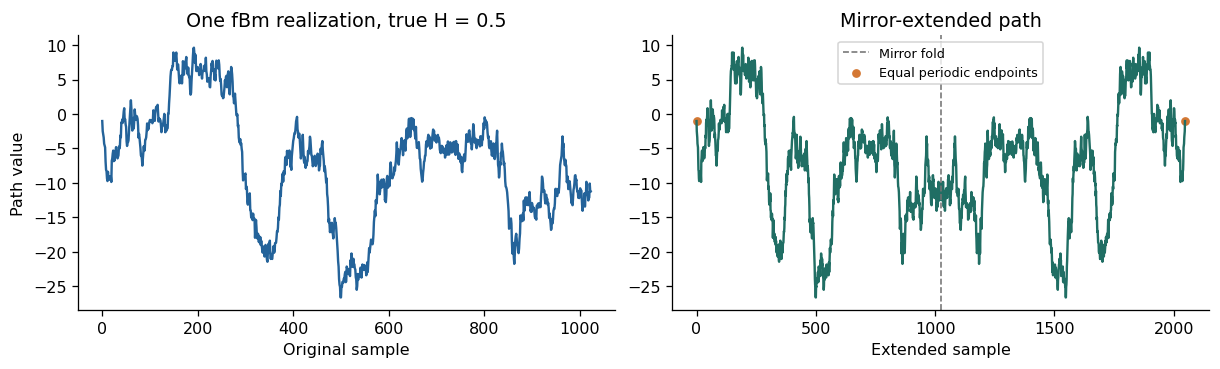

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import cholesky, helmert
from scipy.interpolate import PchipInterpolator
from scipy.optimize import minimize_scalar, minimize, root
from scipy.special import logsumexp, softmax
from scipy.stats import norm

plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})

N = 2048
L = 6
H_TRUE = 0.5
PATH_SEED = 62
SHOT_SEED = 1234
SHOTS_PER_LEVEL = 131072
H_GRID = np.linspace(0.02, 0.98, 65)

J = N.bit_length() - 1
assert N == 2**J and 2 <= L < J
n = N // 2
levels = np.arange(J - 1, J - L - 1, -1)
octaves = np.arange(1, L + 1)
strides = 2**octaves
times = np.arange(1., n + 1)
lag = abs(times[:, None] - times[None, :])

# Eight-tap Symmlet 4 (sym4), in the paper's forward indexing.
# Coefficients: https://ffmpeg.org/doxygen/trunk/af__afwtdn_8c.html (sym4_lp).
h = np.array([-0.07576571478927333, -0.02963552764599851,
              0.49761866763201545, 0.8037387518059161,
              0.29785779560527736, -0.09921954357684722,
              -0.012603967262037833, 0.0322231006040427])
g = (-1.0)**np.arange(h.size) * h[::-1]
# Normalize the coordinates to keep the moment test well scaled.
coordinates = np.arange(h.size, dtype=float) / (h.size - 1)
np.testing.assert_allclose([g @ coordinates**k for k in range(4)],
                           0, atol=2e-11)

def fbm_covariance(H):
    power = times**(2 * H)
    return (power[:, None] + power[None, :] - lag**(2 * H)) / 2

path = cholesky(fbm_covariance(H_TRUE), lower=True) @ np.random.default_rng(PATH_SEED).standard_normal(n)
mirrored = np.r_[path, path[::-1]]

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.1), layout="constrained")
axes[0].plot(np.arange(n), path, color="#24639a")
axes[0].set(title="One fBm realization, true H = 0.5", xlabel="Original sample", ylabel="Path value")
axes[1].plot(np.arange(N), mirrored, color="#206e64")
axes[1].axvline(n - 0.5, ls="--", color="0.45", lw=1, label="Mirror fold")
axes[1].scatter([0, N-1], mirrored[[0, -1]], s=20, color="#d47733", label="Equal periodic endpoints")
axes[1].set(title="Mirror-extended path", xlabel="Extended sample")
axes[1].legend(fontsize=8)
plt.show()

## Coherent shifts and the sym4 lattice

The least significant data bit is the even/odd channel bit. Section 3.2 factors the polyphase analysis into two-channel matrices and delays. In the circuit a delay is a decrement of the position register, controlled on the odd channel. After the rotations and delays, swaps move the channel bit into its Mallat-order position. Open controls restrict each subsequent stage to the approximation subspace.

We use little-endian logical indexing. Data bits come first, shift bits next, and the test ancilla last. The simulator applies the logical gates to the full joint state, including all 64 shifts. The amplitude-encoded path itself is initialized directly.

In [2]:
def lattice_factors(low, high):
    polyphase = np.stack([low.reshape(-1, 2), high.reshape(-1, 2)], axis=1)
    factors = []
    while len(polyphase) > 1:
        left = np.linalg.svd(polyphase[-1])[0][:, 1]
        rotation = np.column_stack((left, [-left[1], left[0]]))
        transformed = rotation.T @ polyphase
        np.testing.assert_allclose(transformed[-1, 0], 0, atol=2e-11)
        np.testing.assert_allclose(transformed[0, 1], 0, atol=2e-11)
        polyphase = np.stack((transformed[:-1, 0], transformed[1:, 1]), axis=1)
        factors.append(rotation)
    # The tabulated filter is rounded. Project the residual factor to O(2)
    # so that every lattice gate remains orthogonal to working precision.
    u, _, vt = np.linalg.svd(polyphase[0])
    np.testing.assert_allclose(polyphase[0], u @ vt, atol=2e-11)
    return [u @ vt, *reversed(factors)]


def counter_operations(register, controls, increment):
    # Highest target first so each carry reads the original lower bits.
    return [
        ("x", bit, None, controls + [(lower, int(increment)) for lower in register[:k]])
        for k, bit in reversed(list(enumerate(register)))
    ]


hadamard = np.array([[1., 1.], [1., -1.]]) / np.sqrt(2)
shift_register = list(range(J, J + L))
ancilla = J + L
basis = np.arange(2**(ancilla + 1))
mirror_ops = [("u", J - 1, hadamard, [])]
mirror_ops += [("x", q, None, [(J - 1, 1)]) for q in range(J - 1)]
shift_ops = [("u", q, hadamard, []) for q in shift_register]
for b, q in enumerate(shift_register):
    shift_ops.extend(counter_operations(list(range(b, J)), [(q, 1)], increment=True))

factors = lattice_factors(h, g)
wavelet_ops = []
for j in levels:
    controls = [(q, 0) for q in range(j + 1, J)]
    for k, rotation in enumerate(factors):
        if k:
            wavelet_ops.extend(counter_operations(list(range(1, j + 1)),
                                                   controls + [(0, 1)], increment=False))
        wavelet_ops.append(("u", 0, rotation, controls))
    wavelet_ops.extend(("swap", q, q + 1, controls) for q in range(j))


def apply_operations(state, operations):
    state = state.copy()
    for kind, bit, arg, controls in operations:
        mask = sum(1 << q for q, _ in controls)
        pattern = sum(value << q for q, value in controls)
        active = basis[(basis & mask) == pattern]
        if kind == "z":
            state[active[(active & (1 << bit)) != 0]] *= -1
            continue
        left = active[(active & (1 << bit)) == 0]
        if kind == "swap":
            left = left[(left & (1 << arg)) != 0]
            right = left ^ ((1 << bit) | (1 << arg))
        else:
            right = left | (1 << bit)
        if kind == "u":
            state[left], state[right] = arg @ np.stack([state[left], state[right]])
        else:
            state[left], state[right] = state[right], state[left]
    return state


initial = np.zeros(basis.size)
initial[:n] = path / np.linalg.norm(path)
mirror_state = apply_operations(initial, mirror_ops)
np.testing.assert_allclose(mirror_state[:N], mirrored / np.linalg.norm(mirrored), atol=1e-13)
qndwt_state = apply_operations(mirror_state, shift_ops + wavelet_ops)
np.testing.assert_allclose(qndwt_state @ qndwt_state, 1., atol=2e-12)

print(f"{J} data + {L} shift + 1 test ancilla = {ancilla+1} logical qubits")
print(f"Coherent shifts: {2**L}; sym4 lattice operations: {len(wavelet_ops)}")

11 data + 6 shift + 1 test ancilla = 18 logical qubits
Coherent shifts: 64; sym4 lattice operations: 204


## Independent filter-bank check and intermediate coefficient plots

The circuit's coefficient branches can be checked in simulation. For scale (r=J-j), every circular translate of the equivalent sym4 detail filter occurs equally often over the (epsilon)-decimated branches. The averaged energy is
$$
E_j=rac{1}{2^r}sum_{	au=0}^{N-1}d_{r,	au}^2.
$$
The factor (2^{-r}) is necessary for comparing level energies with Born probabilities. The diagnostic plot shows the stationary translates directly. Those coefficients are never supplied to the estimator.

Maximum absolute branch-amplitude discrepancy: 3.07e-14


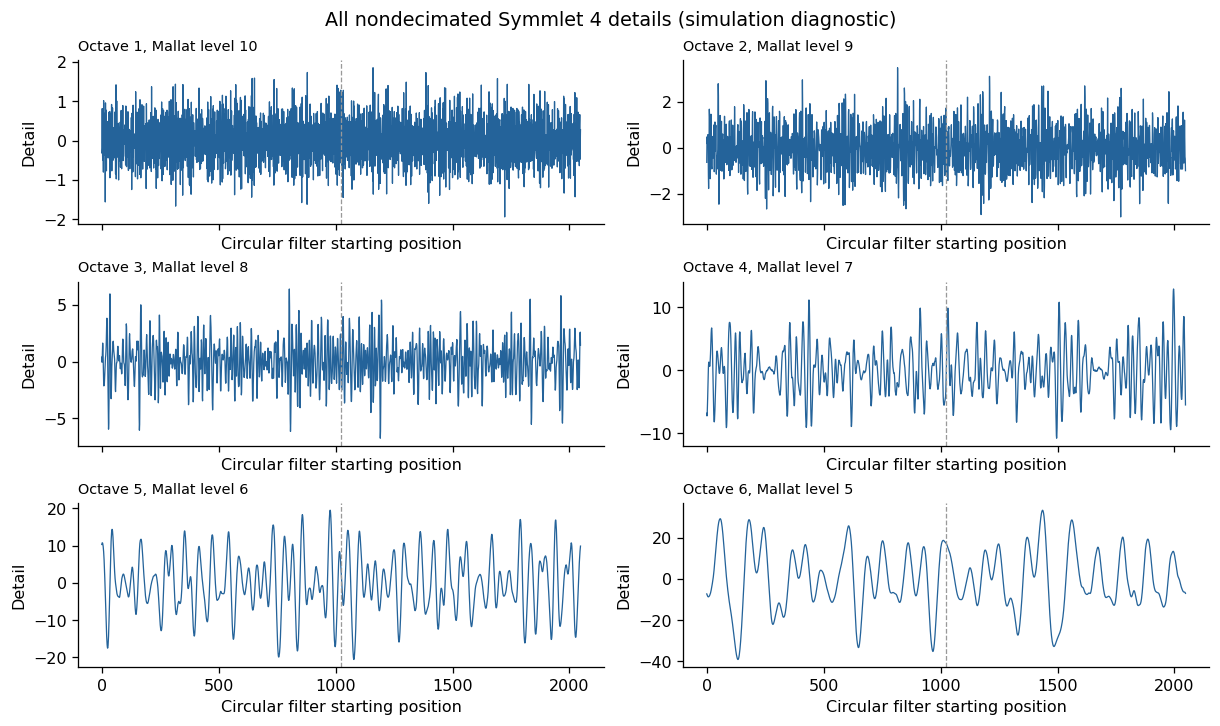

In [3]:
def dilate(filt, step):
    result = np.zeros(1 + (len(filt) - 1) * step)
    result[::step] = filt
    return result


equivalent_details = []
low_chain = np.ones(1)
for r in octaves:
    step = 2**int(r - 1)
    equivalent_details.append(np.convolve(low_chain, dilate(g, step)))
    low_chain = np.convolve(low_chain, dilate(h, step))

fold_indices = np.r_[np.arange(n), np.arange(n - 1, -1, -1)]
operators, stationary_details = [], []
for filt, stride in zip(equivalent_details, strides):
    support = (np.arange(N)[:, None] + np.arange(len(filt))) % N
    design = np.zeros((N, n))
    # Contributions sharing a mirrored source index must be added.
    np.add.at(design, (np.arange(N)[:, None], fold_indices[support]), filt[None, :])
    operators.append(design.T @ design / stride)
    stationary_details.append(design @ path)
operators = np.asarray(operators)
exact_shares = (np.einsum("i,kij,j->k", path, operators, path) / (mirrored @ mirrored))

branches = qndwt_state[:2**ancilla].reshape(2**L, N)
energy_from_branches = np.array([np.sum(branches[:, 2**int(j):2**int(j+1)]**2) for j in levels])
np.testing.assert_allclose(energy_from_branches, exact_shares, rtol=2e-9, atol=2e-12)
# Test indexing as well as energy: for each shift, compare all Mallat coefficients.
def classical_mallat(data):
    blocks = []
    for _ in range(L):
        index = (2*np.arange(data.size//2)[:, None] + np.arange(h.size)) % data.size
        pairs = data[index]
        blocks.append(pairs @ g)
        data = pairs @ h
    return np.concatenate([data, *reversed(blocks)])

reference_branches = np.stack([classical_mallat(np.roll(mirrored, s)) for s in range(2**L)])
reference_branches /= np.linalg.norm(mirrored) * np.sqrt(2**L)
print("Maximum absolute branch-amplitude discrepancy:",
      f"{np.max(abs(branches-reference_branches)):.2e}")
np.testing.assert_allclose(branches, reference_branches, atol=2e-11)

fig, axes = plt.subplots(3, 2, figsize=(10.5, 6.2), sharex=True, layout="constrained")
for r, d, ax in zip(octaves, stationary_details, axes.flat):
    ax.plot(d, lw=0.8, color="#24639a")
    ax.axvline(n-0.5, ls="--", color="0.6", lw=0.8)
    ax.set_title(f"Octave {r}, Mallat level {J-r}", loc="left", fontsize=9)
    ax.set(xlabel="Circular filter starting position", ylabel="Detail")
fig.suptitle("All nondecimated Symmlet 4 details (simulation diagnostic)")
plt.show()

## Hadamard level tests and ancilla counts

For (D_j=I-2P_j), the circuit applies (H), then controlled-(D_j), then (H) to the test ancilla. Its (|1
angle) branch is (P_j|psi
angle), so the ancilla's probability of (1) equals the QNDWT level share. We simulate fresh repetitions by drawing binary outcomes from that marginal of the final statevector. Separate levels use independent shot blocks.

Octave  Mallat level   0 counts   1 counts    Estimated share
     1            10     130899        173           0.001320
     2             9     130869        203           0.001549
     3             8     130616        456           0.003479
     4             7     130140        932           0.007111
     5             6     129098       1974           0.015060
     6             5     127364       3708           0.028290


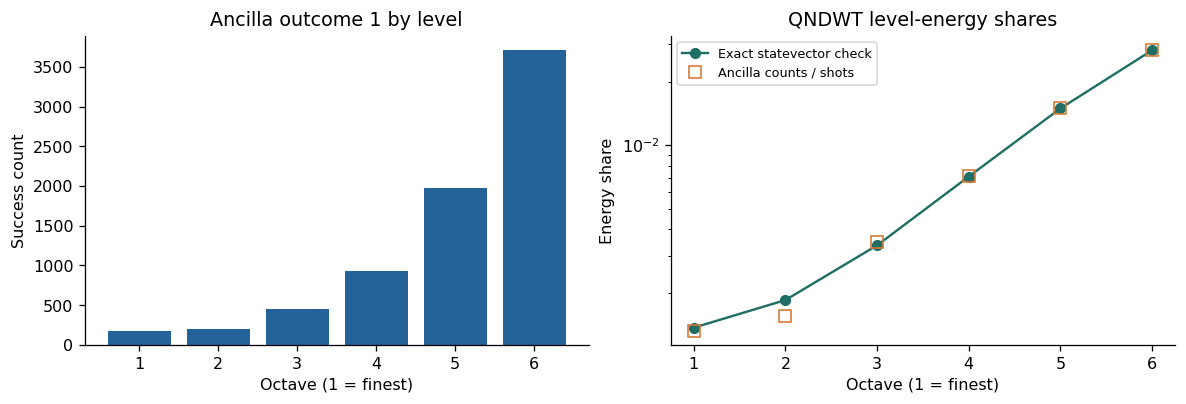

In [4]:
def level_test_operations(j):
    controls = [(ancilla, 1)] + [(q, 0) for q in range(j + 1, J)]
    return [("u", ancilla, hadamard, []), ("z", j, None, controls),
            ("u", ancilla, hadamard, [])]


ancilla_probabilities = []
for j in levels:
    final_state = apply_operations(qndwt_state, level_test_operations(j))
    one_branch = final_state[2**ancilla:]
    ancilla_probabilities.append(one_branch @ one_branch)
np.testing.assert_allclose(ancilla_probabilities, exact_shares, rtol=2e-9, atol=2e-12)
rng = np.random.default_rng(SHOT_SEED)
shots = np.full(L, SHOTS_PER_LEVEL, dtype=int)
counts = np.array([(rng.random(m) < p).sum() for m, p in zip(shots, ancilla_probabilities)])
p_hat = counts / shots
print("Octave  Mallat level   0 counts   1 counts    Estimated share")
for r, j, m, count, share in zip(octaves, levels, shots, counts, p_hat):
    print(f"{r:6d} {j:13d} {m-count:10d} {count:10d} {share:18.6f}")

fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.4), layout="constrained")
axes[0].bar(octaves, counts, color="#24639a")
axes[0].set(title="Ancilla outcome 1 by level", xlabel="Octave (1 = finest)", ylabel="Success count")
axes[1].semilogy(octaves, exact_shares, "o-", color="#206e64", label="Exact statevector check")
positive = counts > 0
axes[1].semilogy(octaves[positive], p_hat[positive], "s", mfc="none", ms=8, color="#d47733",
                 label="Ancilla counts / shots")
axes[1].set(title="QNDWT level-energy shares", xlabel="Octave (1 = finest)", ylabel="Energy share")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xticks(octaves)
plt.show()

## Exact finite-record calibration and estimation

For each candidate (H) we use the unmirrored fBm covariance (Sigma_H) at unit variance. The mirror, equivalent detail filter, and level weight are already included in (A_j). This gives exact finite-record moments (e_j(H)=mathrm{tr}(A_jSigma_H)) and (Gamma_{jk}(H)=2mathrm{tr}(A_jSigma_H A_kSigma_H)). Evaluations between grid points use interpolation.

Natural-log contrasts eliminate the common normalization. The log-GLS fit estimates the covariance from the record term at an unweighted pilot and from the shot term at the observed shares. We also calculate the paper's Poisson–multinomial lognormal count fit using a Laplace approximation in (L-1) dimensions. The count fit accepts individual zero counts. It returns no estimate when the total is zero. Both intervals are approximate; they describe inference for one stochastic record, not just measurement repeatability.

In [5]:
D = helmert(L, full=False)

def moments(H):
    sigma = fbm_covariance(H)
    products = operators @ sigma
    means = np.trace(products, axis1=1, axis2=2)
    cov = 2 * np.einsum("kij,lji->kl", products, products, optimize=True)
    return np.log(means), cov / np.outer(means, means)

calibration = [moments(H) for H in H_GRID]
log_mean = PchipInterpolator(H_GRID, np.stack([item[0] for item in calibration]), axis=0)
rec_cov = PchipInterpolator(H_GRID, np.stack([item[1] for item in calibration]), axis=0)


def grid_minimize(objective):
    values = np.array([objective(H) for H in H_GRID])
    k = int(np.argmin(values))
    if k in (0, len(H_GRID)-1):
        return float(H_GRID[k])
    return float(minimize_scalar(objective, bounds=(H_GRID[k-1], H_GRID[k+1]),
                                 method="bounded").x)


def fit_log_gls(shares, exposures=None):
    if np.any(shares <= 0):
        return None
    z = np.log(shares)
    def residual(H):
        return D @ (z - log_mean(H))
    pilot = grid_minimize(lambda H: residual(H) @ residual(H))
    V = rec_cov(pilot)
    if exposures is not None:
        V = V + np.diag((1 - shares) / (exposures * shares))
    W = np.linalg.inv(D @ V @ D.T)
    def objective(H):
        r = residual(H)
        return r @ W @ r
    estimate = grid_minimize(objective)
    derivative = D @ log_mean.derivative()(estimate)
    se = float(1 / np.sqrt(derivative @ W @ derivative))
    interval = (estimate - norm.ppf(.975)*se, estimate + norm.ppf(.975)*se)
    return dict(H=estimate, pilot=pilot, se=se, interval=interval, objective=objective)


def fit_counts_laplace(counts, exposures):
    total = counts.sum()
    if total == 0:
        return None

    def log_likelihood(H):
        A = D @ rec_cov(H) @ D.T
        A_inv = np.linalg.inv(A)
        offset = np.log(exposures) + log_mean(H)

        def target(c):
            logits = offset + D.T @ c
            prob = softmax(logits)
            value = -counts @ (logits - logsumexp(logits)) + (c @ A_inv @ c) / 2
            grad = -D @ (counts - total*prob) + A_inv @ c
            return value, grad

        mode = minimize(target, np.zeros(L - 1), jac=True, method="BFGS",
                        options={"gtol": 1e-7}).x
        def curvature_at(c):
            prob = softmax(offset + D.T @ c)
            return A_inv + total * D @ (np.diag(prob) - np.outer(prob, prob)) @ D.T

        # Polish the score equation when the large count objective loses
        # enough floating-point resolution to stall the line search.
        if np.linalg.norm(target(mode)[1], ord=np.inf) > 1e-6:
            polished = root(lambda c: target(c)[1], mode, jac=curvature_at)
            mode = polished.x
        value, grad = target(mode)
        if np.linalg.norm(grad, ord=np.inf) > 1e-5:
            raise RuntimeError("Contrast-mode optimization did not converge.")
        return -value - (np.linalg.slogdet(A)[1]
                         + np.linalg.slogdet(curvature_at(mode))[1]) / 2

    estimate = grid_minimize(lambda H: -log_likelihood(H))
    return dict(H=estimate, log_likelihood=log_likelihood)

gls_fit = fit_log_gls(p_hat, shots)
count_fit = fit_counts_laplace(counts, shots)
exact_fit = fit_log_gls(exact_shares)  # diagnostic only
print(f"Generating H                 {H_TRUE:.6f}")
print(f"Exact-share GLS diagnostic   {exact_fit['H']:.6f}")
if gls_fit is not None:
    lo, hi = gls_fit["interval"]
    print(f"Ancilla log-GLS estimate      {gls_fit['H']:.6f}")
    print(f"Approximate 95% Wald CI       [{lo:.4f}, {hi:.4f}]")
if count_fit is not None:
    print(f"Ancilla count-fit estimate    {count_fit['H']:.6f}")
else:
    print("All ancilla counts are zero; this shot budget yielded no estimate.")

Generating H                 0.500000
Exact-share GLS diagnostic   0.498832
Ancilla log-GLS estimate      0.514592
Approximate 95% Wald CI       [0.4617, 0.5675]
Ancilla count-fit estimate    0.515039


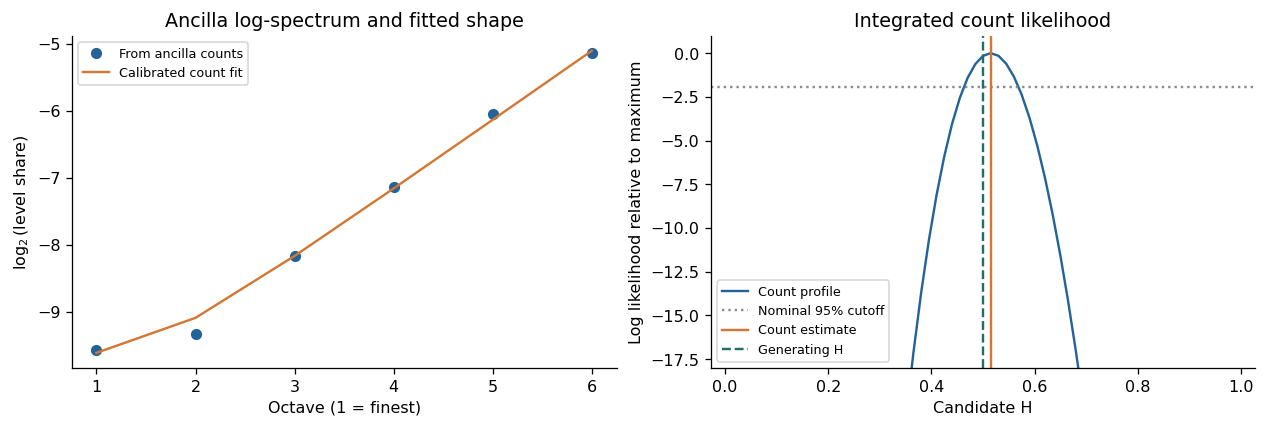

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.9, 3.6), layout="constrained")
if positive.any():
    axes[0].plot(octaves[positive], np.log2(p_hat[positive]), "o", color="#24639a",
                 label="From ancilla counts")
if count_fit is not None:
    b = log_mean(count_fit["H"])
    # This intercept is only for placing the fitted energy curve on the share axis.
    offset = np.log(counts.sum()) - logsumexp(np.log(shots) + b)
    axes[0].plot(octaves, (b + offset) / np.log(2), "-", color="#d47733", label="Calibrated count fit")
axes[0].set(title="Ancilla log-spectrum and fitted shape", xlabel="Octave (1 = finest)",
            ylabel=r"$\log_2$(level share)", xticks=octaves)
if positive.any():
    axes[0].legend(fontsize=8)
if count_fit is not None:
    profile = np.array([count_fit["log_likelihood"](H) for H in H_GRID])
    profile -= count_fit["log_likelihood"](count_fit["H"])
    axes[1].plot(H_GRID, profile, color="#24639a", label="Count profile")
    axes[1].axhline(-1.92, ls=":", color="0.55", label="Nominal 95% cutoff")
    axes[1].axvline(count_fit["H"], color="#d47733", label="Count estimate")
    axes[1].set_ylim(max(profile.min(), -18), 1)
axes[1].axvline(H_TRUE, ls="--", color="#206e64", label="Generating H")
axes[1].set(title="Integrated count likelihood", xlabel="Candidate H", ylabel="Log likelihood relative to maximum")
axes[1].legend(fontsize=8)
plt.show()

The two estimates use the same one-record ancilla dataset. Their discrepancy from 0.5 includes variability of this particular fBm realization. The exact-share fit helps isolate that part of the discrepancy. Changing the shot seed changes the measurement outcomes on the same path; changing the path seed generates a new realization.

## Appendix implementation in Qiskit 2.x

The gate lists above describe the same logical sequence as the manuscript appendix. Each entry specifies an operation, its target, an optional matrix or angle, and control conditions. A pair such as `(5, 0)` means that qubit 5 must be in state zero. The NumPy simulator interprets these entries directly. The emitter below instead appends Qiskit gates, producing a circuit that can be drawn, simulated, or transpiled for a chosen backend.

The notebook's `shift_ops` already begins with the Hadamards that prepare the uniform shift register. The appendix's `shift_ops` implements the controlled addition alone, so its Hadamards must be added when using that function by itself. The mirror is implemented by gates **after** preparing the original path. For measurement of one selected level, only the ancilla is read, and its probability of 1 equals the level's energy share.

This section is optional. In a kernel with Qiskit 2.x, run the cells below after the NumPy workflow. To install Qiskit in the active notebook kernel, use `%pip install "qiskit>=2,<3"` and restart the kernel if needed.

In [7]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PhaseGate, StatePreparation, SwapGate, UnitaryGate, XGate, ZGate
from qiskit.quantum_info import Statevector


def append_gate_list(circuit, operations):
    # The NumPy lists use a uniform four-field format.
    for kind, target, value, controls in operations:
        targets = [int(target)]
        if kind == "u":
            gate = UnitaryGate(value)
        elif kind == "p":
            gate = PhaseGate(value)
        elif kind == "swap":
            gate = SwapGate()
            targets.append(int(value))
        elif kind == "x":
            gate = XGate()
        elif kind == "z":
            gate = ZGate()
        else:
            raise ValueError(f"Unsupported gate type: {kind}")
        if controls:
            control_qubits = [int(q) for q, _ in controls]
            # The first qubit in the control list is bit zero of ctrl_state.
            ctrl_state = sum(int(bit) << k for k, (_, bit) in enumerate(controls))
            gate = gate.control(len(control_qubits), ctrl_state=ctrl_state)
            targets = control_qubits + targets
        circuit.append(gate, targets)


def make_level_circuit(level, measure=False):
    if level not in levels:
        raise ValueError(f"Choose a Mallat level from {levels.tolist()}.")
    circuit = QuantumCircuit(ancilla + 1, int(measure), name=f"QNDWT_j{level}")
    circuit.append(StatePreparation(path / np.linalg.norm(path)), list(range(J - 1)))
    append_gate_list(circuit, mirror_ops + shift_ops + wavelet_ops + level_test_operations(level))
    if measure:
        circuit.measure(ancilla, 0)
    return circuit


mallat_level = int(levels[0])
level_circuit = make_level_circuit(mallat_level, measure=True)
print(f"Mallat level j={mallat_level}; {level_circuit.num_qubits} logical qubits; "
      f"{len(level_circuit.data)} logical instructions")
# For a smaller demonstration, set N=64 and L=3 in the first cell, then Run All.
# print(level_circuit.draw(output="text", fold=120))

Mallat level j=10; 18 logical qubits; 277 logical instructions


### Cross-check the Qiskit ancilla probability

For a small worked circuit, set `N = 64` (32 original samples after accounting for mirroring) and `L = 3` in the first cell, then run the notebook from the beginning. The following check transpiles to a generic `u,cx` basis, calculates the exact ancilla probability, and compares it with the independent NumPy gate-list result. Its CNOT count is for **generic synthesis**, before hardware connectivity and routing. The full (N=2048) circuit is built in the cell above. The exact Qiskit check is limited by default to smaller input sizes to keep it practical.

In [8]:
if N <= 128:
    unitary_circuit = make_level_circuit(mallat_level)
    compiled = transpile(unitary_circuit, basis_gates=["u", "cx"],
                         optimization_level=1, seed_transpiler=62)
    p_one = Statevector.from_instruction(compiled).probabilities([ancilla])[1]
    expected = ancilla_probabilities[list(levels).index(mallat_level)]
    np.testing.assert_allclose(p_one, expected, rtol=1e-8, atol=1e-10)
    print(f"P(ancilla = 1), Qiskit {p_one:.10f}; NumPy {expected:.10f}")
    print(f"Generic synthesis: {compiled.count_ops().get('cx', 0)} CNOT gates "
          f"and depth {compiled.depth()}.")
else:
    print("Logical circuit is ready. For a quick Qiskit statevector check, use N=64 and L=3.")

Logical circuit is ready. For a quick Qiskit statevector check, use N=64 and L=3.
